<a href="https://colab.research.google.com/github/BuvanAlfarezy/BuvanAlfarezy_Test4_Analisis-Sentimen/blob/main/BuvanAlfarezy_Test4_Analisis_Sentimen_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn wordcloud Sastrawi streamlit joblib openpyxl

In [ ]:
!apt-get update -qq
!npx playwright install-deps chromium


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴Need to install the following packages:
playwright@1.65.1
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏Installing dependencies...
Hit:1 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:2 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:5 https://cli.github.com/packages stable InRelease
Hit:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:7 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelea

In [ ]:
import shutil
import subprocess

if shutil.which("node") is None or shutil.which("npm") is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "nodejs", "npm"], check=True)

print("Node:", subprocess.check_output(["node", "--version"], text=True).strip())
print("npm:", subprocess.check_output(["npm", "--version"], text=True).strip())

Node: v22.23.4
npm: 10.8.2


In [ ]:
import os
import re
import json
import glob
import time
import joblib
import warnings
import subprocess
from pathlib import Path
from getpass import getpass
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
PROJECT_DIR = Path("/content/analisis_sentimen_kebakaran_hutan")
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
VIS_DIR = PROJECT_DIR / "visualisasi"

for folder in [DATA_DIR, MODEL_DIR, VIS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Folder proyek:", PROJECT_DIR)

Folder proyek: /content/analisis_sentimen_kebakaran_hutan


In [13]:
twitter_auth_token = getpass("Masukkan cookie X auth_token: ").strip()

if len(twitter_auth_token) < 30:
    raise ValueError("Token tampaknya tidak valid atau belum dimasukkan.")

print("Token diterima. Nilainya tidak ditampilkan.")

Masukkan cookie X auth_token: ··········
Token diterima. Nilainya tidak ditampilkan.


In [14]:
search_keyword = (
    '("kebakaran hutan" OR karhutla OR "kebakaran lahan" OR "hutan terbakar") '
    'lang:id -filter:retweets'
)

command = [
    "npx", "-y", "tweet-harvest@2.7.1",
    "--token", twitter_auth_token,
    "--search-keyword", search_keyword,
    "--tab", "LATEST",
    "--limit", "500",
    "--output-filename", "tweet_data",
    "--export-format", "csv"
]

print("Memulai crawling Tweet-Harvest...")
result = subprocess.run(command, cwd="/content", text=True)
print("Exit code:", result.returncode)

# Lokasi output default menurut kode Tweet-Harvest
crawled_file = Path("/content/tweets-data/tweet_data.csv")
if not crawled_file.exists():
    candidates = list(Path("/content/tweets-data").glob("tweet_data*.csv"))
    if candidates:
        crawled_file = candidates[0]
    else:
        raise FileNotFoundError(
            "CSV hasil crawling tidak ditemukan. Periksa log Tweet-Harvest. "
            "Jika muncul TimeoutError pada selector pencarian X, kemungkinan UI X berubah."
        )

print("File hasil crawling:", crawled_file)

Memulai crawling Tweet-Harvest...
Exit code: 0
File hasil crawling: /content/tweets-data/tweet_data.csv


In [15]:
from pathlib import Path

output_dir = Path("/content/tweets-data")

csv_files = list(output_dir.glob("*.csv"))

for file in csv_files:
    print(f"File: {file}")
    print(f"Ukuran: {file.stat().st_size / 1024:.2f} KB")

File: /content/tweets-data/tweet_data.csv
Ukuran: 113.43 KB


In [16]:
raw_df = pd.read_csv(crawled_file)
print("Ukuran data mentah:", raw_df.shape)
print("Kolom tersedia:", raw_df.columns.tolist())
display(raw_df.head())

Ukuran data mentah: (421, 15)
Kolom tersedia: ['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username']


,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username
0,430238247927554048,2014-02-03T07:16:06.000Z,0,Karhutla di Bengkalis Meluas http://t.co/N6znx...,430238247927554048,NaN,NaN,in,NaN,0,0,0,https://x.com/infoRIAU/status/430238247927554048,172425532,infoRIAU
1,430223661107146752,2014-02-03T06:18:08.000Z,0,"Hasil Pantauan Satelit, Kebakaran Lahan di Ria...",430223661107146752,NaN,NaN,in,NaN,0,0,0,https://x.com/infoRIAU/status/430223661107146752,172425532,infoRIAU
2,430210745515520000,2014-02-03T05:26:49.000Z,1,Besok Dishut Turunkan Personel ke Kawasan Keba...,430210745515520000,NaN,NaN,in,NaN,0,0,0,https://x.com/infoRIAU/status/430210745515520000,172425532,infoRIAU
3,430170804634931200,2014-02-03T02:48:06.000Z,0,Pemadaman Karhutla di Bengkalis Fokus Pada Dua...,430170804634931200,NaN,NaN,in,NaN,0,0,1,https://x.com/infoRIAU/status/430170804634931200,172425532,infoRIAU
4,429986240264282114,2014-02-02T14:34:43.000Z,0,Karhutla di Bengkalis Terus Meluas http://t.co...,429986240264282114,NaN,NaN,in,NaN,0,0,0,https://x.com/infoRIAU/status/429986240264282114,172425532,infoRIAU


In [17]:
required_columns = ["created_at", "username", "full_text"]
missing_columns = [col for col in required_columns if col not in raw_df.columns]
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

df = raw_df[required_columns].copy()
df = df.dropna(subset=["full_text"])
df["full_text"] = df["full_text"].astype(str).str.strip()
df = df[df["full_text"] != ""]
df = df.drop_duplicates(subset=["full_text"]).reset_index(drop=True)

raw_output = DATA_DIR / "tweet_data.csv"
df.to_csv(raw_output, index=False, encoding="utf-8-sig")

print("Jumlah data setelah deduplikasi:", len(df))
print("Dataset mentah disimpan:", raw_output)
if len(df) < 300:
    print("PERINGATAN: data belum mencapai 300 tweet. Lakukan crawling tambahan sebelum analisis final.")
display(df.head())

Jumlah data setelah deduplikasi: 417
Dataset mentah disimpan: /content/analisis_sentimen_kebakaran_hutan/data/tweet_data.csv


,created_at,username,full_text
0,2014-02-03T07:16:06.000Z,infoRIAU,Karhutla di Bengkalis Meluas http://t.co/N6znx...
1,2014-02-03T06:18:08.000Z,infoRIAU,"Hasil Pantauan Satelit, Kebakaran Lahan di Ria..."
2,2014-02-03T05:26:49.000Z,infoRIAU,Besok Dishut Turunkan Personel ke Kawasan Keba...
3,2014-02-03T02:48:06.000Z,infoRIAU,Pemadaman Karhutla di Bengkalis Fokus Pada Dua...
4,2014-02-02T14:34:43.000Z,infoRIAU,Karhutla di Bengkalis Terus Meluas http://t.co...


In [34]:
# Ini upluad dataset yang sudah dilakukan labeling
uploaded = files.upload()
if not uploaded:
    raise ValueError("Belum ada file yang di-upload.")

uploaded_name = next(iter(uploaded))
file_bytes = uploaded[uploaded_name]

if uploaded_name.lower().endswith(".csv"):
    df = pd.read_csv(io.BytesIO(file_bytes))
elif uploaded_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(file_bytes))
else:
    raise ValueError("Format file harus CSV atau Excel.")

print("File di-upload:", uploaded_name)
print("Ukuran awal:", df.shape)
display(df.head())

Saving dataset_sentimen.csv to dataset_sentimen (1).csv
File di-upload: dataset_sentimen (1).csv
Ukuran awal: (382, 5)


,created_at,username,full_text,clean_text,sentimen
0,2014-02-03T07:16:06.000Z,infoRIAU,Karhutla di Bengkalis Meluas http://t.co/N6znx...,kebakaran hutan bengkalis meluas riaupos,negatif
1,2014-02-03T06:18:08.000Z,infoRIAU,"Hasil Pantauan Satelit, Kebakaran Lahan di Ria...",hasil pantauan satelit kebakaran lahan riau mu...,positif
2,2014-02-03T05:26:49.000Z,infoRIAU,Besok Dishut Turunkan Personel ke Kawasan Keba...,besok dishut turunkan personel kawasan kebakar...,netral
3,2014-02-03T02:48:06.000Z,infoRIAU,Pemadaman Karhutla di Bengkalis Fokus Pada Dua...,pemadaman kebakaran hutan bengkalis fokus titi...,netral
4,2014-02-02T14:34:43.000Z,infoRIAU,Karhutla di Bengkalis Terus Meluas http://t.co...,kebakaran hutan bengkalis terus meluas goriau,negatif


In [35]:
df.columns = [str(col).strip().lower() for col in df.columns]

column_aliases = {
    "text": "full_text",
    "tweet": "full_text",
    "isi_tweet": "full_text",
    "label": "sentimen",
    "sentiment": "sentimen",
    "label_sentimen": "sentimen"
}
df = df.rename(columns=column_aliases)

if "full_text" not in df.columns:
    raise ValueError("Kolom teks tidak ditemukan. Gunakan full_text atau text.")
if "sentimen" not in df.columns:
    raise ValueError("Kolom label tidak ditemukan. Gunakan sentimen atau label.")

for col in ["created_at", "username"]:
    if col not in df.columns:
        df[col] = ""

df = df[["created_at", "username", "full_text", "sentimen"]].copy()
df = df.dropna(subset=["full_text"]).copy()
df["full_text"] = df["full_text"].astype(str).str.strip()
df = df[df["full_text"] != ""].copy()

label_mapping = {
    "positif": "positif", "positive": "positif",
    "netral": "netral", "neutral": "netral",
    "negatif": "negatif", "negative": "negatif"
}
normalized_labels = df["sentimen"].astype("string").str.strip().str.lower().map(label_mapping)
invalid_mask = normalized_labels.isna()

if invalid_mask.any():
    print("Jumlah label kosong/tidak valid:", int(invalid_mask.sum()))
    display(df.loc[invalid_mask, ["full_text", "sentimen"]].head(30))
    raise ValueError("Perbaiki semua label kosong/tidak valid di Excel, lalu upload ulang.")

df["sentimen"] = normalized_labels.astype(str)

# Periksa tweet duplikat yang diberi label berbeda sebelum membuang duplikat.
duplicate_label_counts = df.groupby("full_text")["sentimen"].nunique()
conflicting_texts = duplicate_label_counts[duplicate_label_counts > 1].index
if len(conflicting_texts) > 0:
    print("Ada teks duplikat dengan label yang berbeda:")
    display(df[df["full_text"].isin(conflicting_texts)][["full_text", "sentimen"]].head(30))
    raise ValueError("Samakan label pada tweet duplikat, lalu upload ulang.")

df = df.drop_duplicates(subset=["full_text"]).reset_index(drop=True)

print("Jumlah data:", len(df))
print("Distribusi label manual:")
display(df["sentimen"].value_counts().reindex(["positif", "netral", "negatif"], fill_value=0).to_frame("jumlah"))
display(df.head())

Jumlah data: 382
Distribusi label manual:


,jumlah
sentimen,
positif,79
netral,180
negatif,123


,created_at,username,full_text,sentimen
0,2014-02-03T07:16:06.000Z,infoRIAU,Karhutla di Bengkalis Meluas http://t.co/N6znx...,negatif
1,2014-02-03T06:18:08.000Z,infoRIAU,"Hasil Pantauan Satelit, Kebakaran Lahan di Ria...",positif
2,2014-02-03T05:26:49.000Z,infoRIAU,Besok Dishut Turunkan Personel ke Kawasan Keba...,netral
3,2014-02-03T02:48:06.000Z,infoRIAU,Pemadaman Karhutla di Bengkalis Fokus Pada Dua...,netral
4,2014-02-02T14:34:43.000Z,infoRIAU,Karhutla di Bengkalis Terus Meluas http://t.co...,negatif


In [37]:
%%writefile /content/analisis_sentimen_kebakaran_hutan/preprocessing.py
import re
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

NORMALISASI_KATA = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak",
    "nggak": "tidak", "enggak": "tidak", "ngga": "tidak",
    "yg": "yang", "dgn": "dengan", "utk": "untuk",
    "krn": "karena", "dlm": "dalam", "tp": "tapi",
    "bgt": "banget", "sm": "sama", "karhutla": "kebakaran hutan"
}

_STOPWORDS = set(StopWordRemoverFactory().get_stop_words())
# Negasi dipertahankan karena dapat mengubah makna sentimen.
_STOPWORDS -= {"tidak", "bukan", "belum", "jangan", "tak"}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    # Hapus simbol #, tetapi pertahankan isi hashtag sebagai kata.
    text = re.sub(r"#", "", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    words = [NORMALISASI_KATA.get(word, word) for word in text.split()]
    words = [word for word in words if word not in _STOPWORDS]
    return " ".join(words).strip()

Overwriting /content/analisis_sentimen_kebakaran_hutan/preprocessing.py


In [38]:
import sys
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from preprocessing import clean_text

df["clean_text"] = df["full_text"].apply(clean_text)
df = df[df["clean_text"].str.strip() != ""].copy()
df = df.reset_index(drop=True)

print("Jumlah data setelah preprocessing:", len(df))
display(df[["full_text", "clean_text", "sentimen"]].head(15))
if len(df) < 300:
    print("PERINGATAN: jumlah data setelah preprocessing kurang dari 300 tweet.")

Jumlah data setelah preprocessing: 382


,full_text,clean_text,sentimen
0,Karhutla di Bengkalis Meluas http://t.co/N6znx...,kebakaran hutan bengkalis meluas riaupos,negatif
1,"Hasil Pantauan Satelit, Kebakaran Lahan di Ria...",hasil pantauan satelit kebakaran lahan riau mu...,positif
2,Besok Dishut Turunkan Personel ke Kawasan Keba...,besok dishut turunkan personel kawasan kebakar...,netral
3,Pemadaman Karhutla di Bengkalis Fokus Pada Dua...,pemadaman kebakaran hutan bengkalis fokus titi...,netral
4,Karhutla di Bengkalis Terus Meluas http://t.co...,kebakaran hutan bengkalis terus meluas goriau,negatif
5,Via @_indrapwijaya_: di sekitaran Kantor TVRI ...,via sekitaran kantor tvri rumbai kebakaran hut...,netral
6,hah? :o @_indrapwijaya_: di sekitaran Kantor ...,hah o sekitaran kantor tvri rumbai kebakaran l...,negatif
7,JMGR Tuding Kebakaran Lahan PT NSP Akibat Kela...,jmgr tuding kebakaran lahan pt nsp akibat kela...,netral
8,Kebakaran Lahan di Bengkalis Meluas http://t.c...,kebakaran lahan bengkalis meluas tribunpekanbaru,negatif
9,Kebakaran Hutan di Bengkalis Terus Meluas http...,kebakaran hutan bengkalis terus meluas halloriau,negatif


In [39]:
label_order = ["positif", "netral", "negatif"]
sentiment_counts = df["sentimen"].value_counts().reindex(label_order, fill_value=0)

print("Distribusi label manual:")
display(sentiment_counts.rename("jumlah_tweet").to_frame())
print("Persentase label:")
display((sentiment_counts / len(df) * 100).round(2).rename("persentase").to_frame())

# Tinjau beberapa sampel dan pastikan label tetap berasal dari file manual.
display(df[["full_text", "clean_text", "sentimen"]].sample(min(25, len(df)), random_state=RANDOM_STATE))

if df["sentimen"].nunique() != 3:
    print("PERINGATAN: dataset belum memuat ketiga kategori sentimen.")
if sentiment_counts.min() < 2:
    print("PERINGATAN: ada kelas dengan kurang dari 2 data; stratified split mungkin gagal.")

Distribusi label manual:


,jumlah_tweet
sentimen,
positif,79
netral,180
negatif,123


Persentase label:


,persentase
sentimen,
positif,20.68
netral,47.12
negatif,32.20


,full_text,clean_text,sentimen
280,Indonesia Mestinya Bisa Berbuat Lebih Untuk ce...,indonesia mestinya berbuat lebih cegah kebakar...,netral
248,Pesawat Rusia akan Bantu Padamkan Karhutla htt...,pesawat rusia bantu padamkan kebakaran hutan h...,positif
218,BNPB: Titik Api Kebakaran Hutan di Riau Mulai ...,bnpb titik api kebakaran hutan riau mulai berk...,positif
327,jadi api kebakaran hutan belum padam juga??,jadi api kebakaran hutan belum padam,negatif
56,"Dinilai abai tangani kebakaran hutan, Walhi gu...",dinilai abai tangani kebakaran hutan walhi gug...,negatif
370,"""kebakaran hutan dan lahan di Pelalawan"" (foto...",kebakaran hutan lahan pelalawan foto nbc news,netral
33,Asap Kebakaran Lahan di Lampung Mulai Ganggu P...,asap kebakaran lahan lampung mulai ganggu peng...,negatif
114,Helikopter Militer Bosnia Padamkan Kebakaran H...,helikopter militer bosnia padamkan kebakaran h...,positif
373,"""foto udara: salah satu kebakaran lahan / huta...",foto udara salah satu kebakaran lahan hutan ri...,netral
237,"Hujan Buatan, Langkah BPPT Atasi Kebakaran Hut...",hujan buatan langkah bppt atasi kebakaran hutan,positif


In [40]:
audit_columns = ["full_text", "clean_text", "sentimen"]
display(df[audit_columns].sample(min(25, len(df)), random_state=RANDOM_STATE))

,full_text,clean_text,sentimen
280,Indonesia Mestinya Bisa Berbuat Lebih Untuk ce...,indonesia mestinya berbuat lebih cegah kebakar...,netral
248,Pesawat Rusia akan Bantu Padamkan Karhutla htt...,pesawat rusia bantu padamkan kebakaran hutan h...,positif
218,BNPB: Titik Api Kebakaran Hutan di Riau Mulai ...,bnpb titik api kebakaran hutan riau mulai berk...,positif
327,jadi api kebakaran hutan belum padam juga??,jadi api kebakaran hutan belum padam,negatif
56,"Dinilai abai tangani kebakaran hutan, Walhi gu...",dinilai abai tangani kebakaran hutan walhi gug...,negatif
370,"""kebakaran hutan dan lahan di Pelalawan"" (foto...",kebakaran hutan lahan pelalawan foto nbc news,netral
33,Asap Kebakaran Lahan di Lampung Mulai Ganggu P...,asap kebakaran lahan lampung mulai ganggu peng...,negatif
114,Helikopter Militer Bosnia Padamkan Kebakaran H...,helikopter militer bosnia padamkan kebakaran h...,positif
373,"""foto udara: salah satu kebakaran lahan / huta...",foto udara salah satu kebakaran lahan hutan ri...,netral
237,"Hujan Buatan, Langkah BPPT Atasi Kebakaran Hut...",hujan buatan langkah bppt atasi kebakaran hutan,positif


In [41]:
normalized_csv = DATA_DIR / "dataset_sentimen.csv"
normalized_xlsx = DATA_DIR / "dataset_sentimen.xlsx"

df.to_csv(normalized_csv, index=False, encoding="utf-8-sig")
df.to_excel(normalized_xlsx, index=False)

print("CSV:", normalized_csv)
print("Excel:", normalized_xlsx)
print("Jumlah data akhir:", len(df))
if len(df) < 300:
    print("PERINGATAN: jumlah data akhir kurang dari 300.")

CSV: /content/analisis_sentimen_kebakaran_hutan/data/dataset_sentimen.csv
Excel: /content/analisis_sentimen_kebakaran_hutan/data/dataset_sentimen.xlsx
Jumlah data akhir: 382


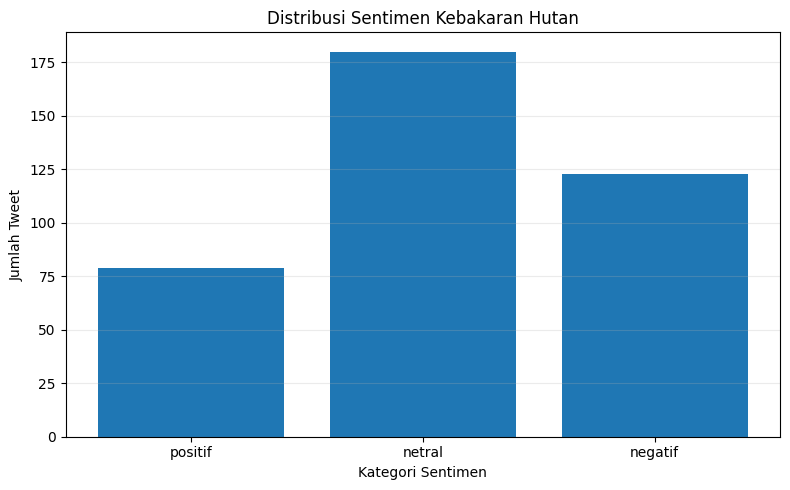

In [42]:
plt.figure(figsize=(8, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Distribusi Sentimen Kebakaran Hutan")
plt.xlabel("Kategori Sentimen")
plt.ylabel("Jumlah Tweet")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(VIS_DIR / "distribusi_bar.png", dpi=300, bbox_inches="tight")
plt.show()

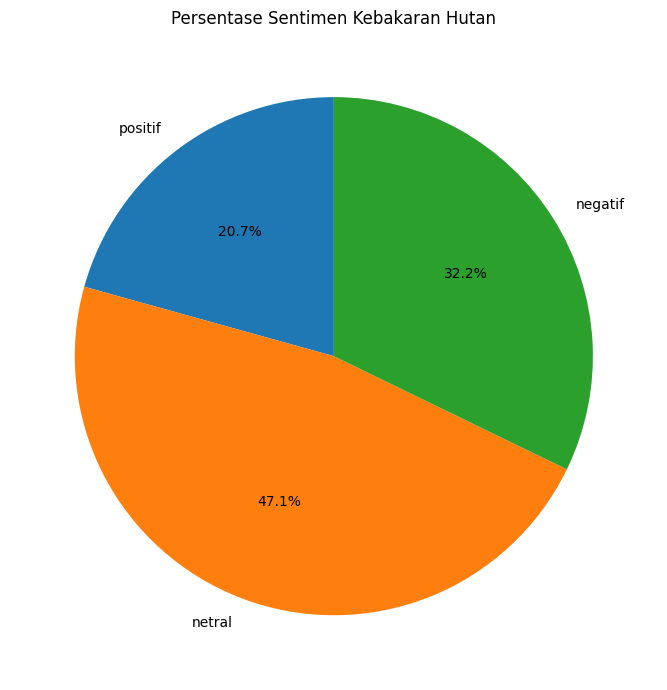

In [43]:
plt.figure(figsize=(7, 7))
plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Persentase Sentimen Kebakaran Hutan")
plt.tight_layout()
plt.savefig(VIS_DIR / "distribusi_pie.png", dpi=300, bbox_inches="tight")
plt.show()

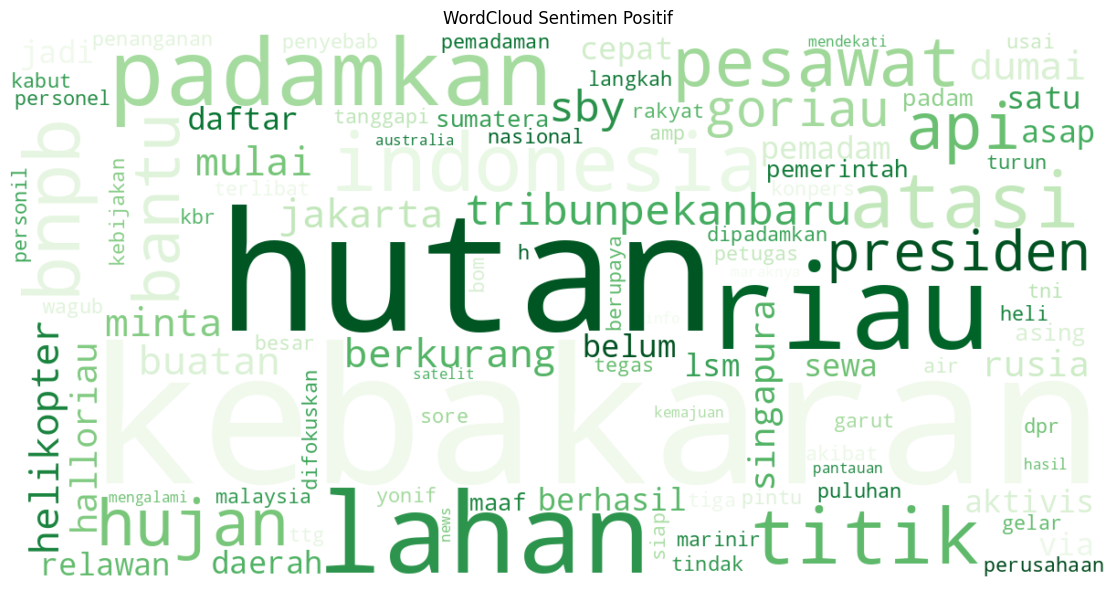

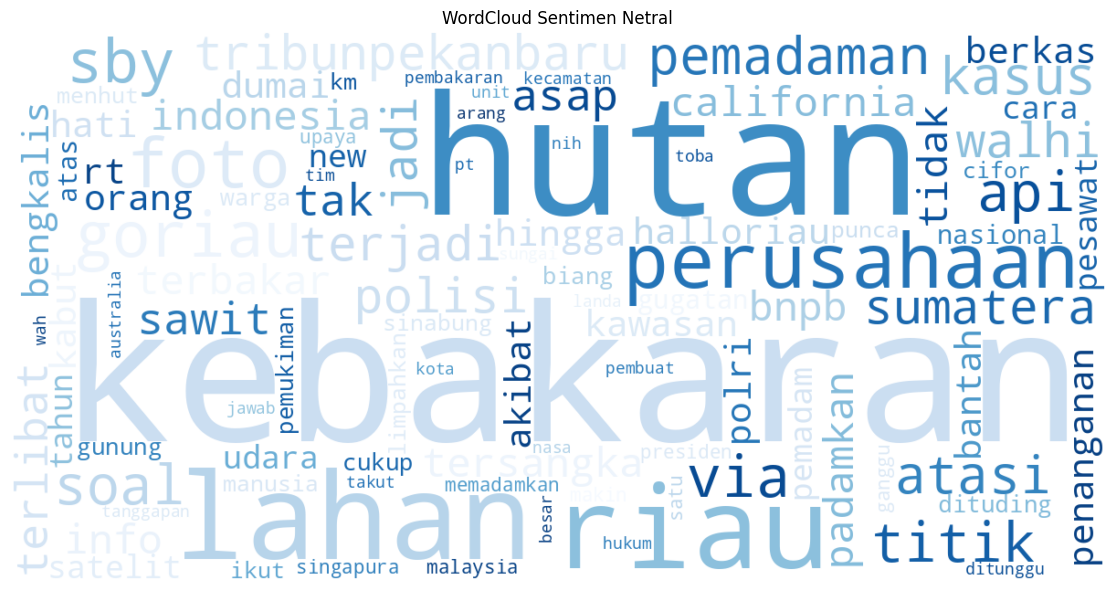

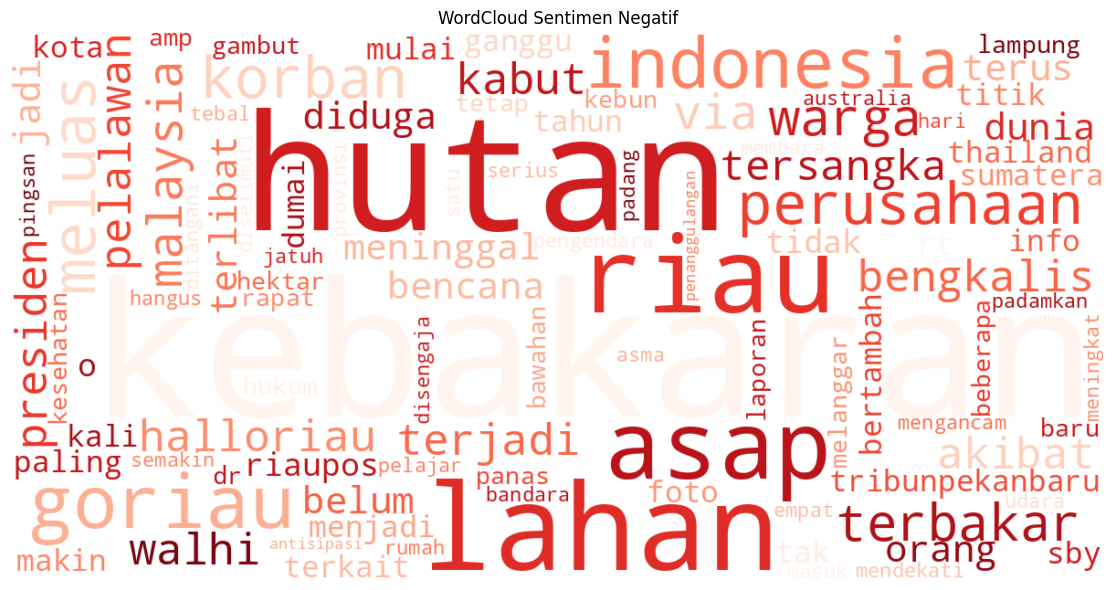

In [44]:
colormaps = {"positif": "Greens", "netral": "Blues", "negatif": "Reds"}

for category in label_order:
    text_data = " ".join(df.loc[df["sentimen"] == category, "clean_text"].astype(str))
    if not text_data.strip():
        print(f"Tidak ada teks untuk kategori {category}.")
        continue

    wc = WordCloud(
        width=1200, height=600, background_color="white",
        colormap=colormaps[category], max_words=100, collocations=False
    ).generate(text_data)

    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"WordCloud Sentimen {category.capitalize()}")
    plt.tight_layout()
    plt.savefig(VIS_DIR / f"wordcloud_{category}.png", dpi=300, bbox_inches="tight")
    plt.show()

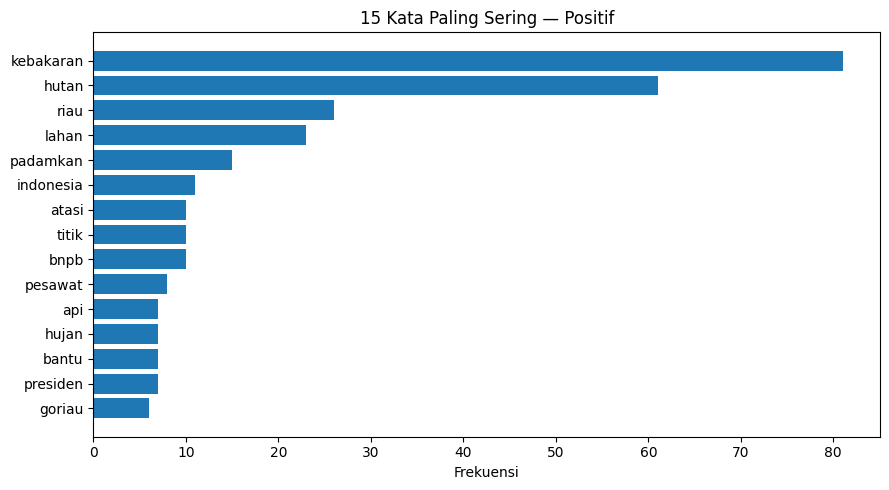

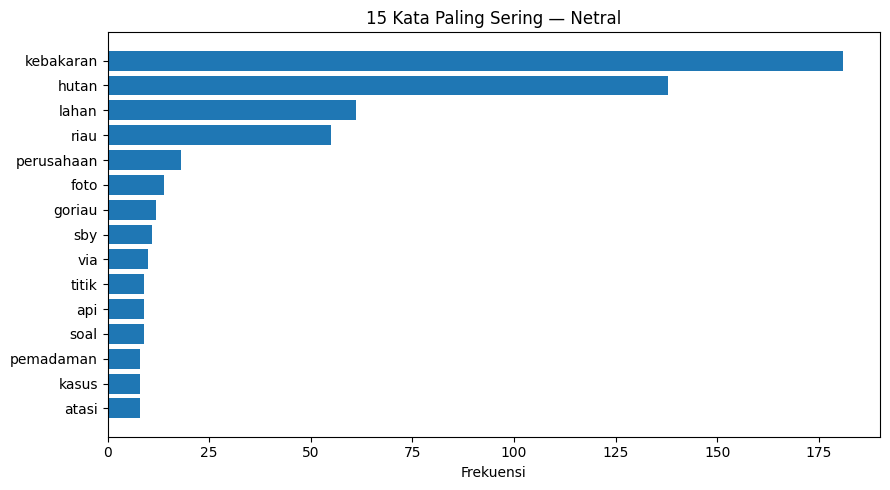

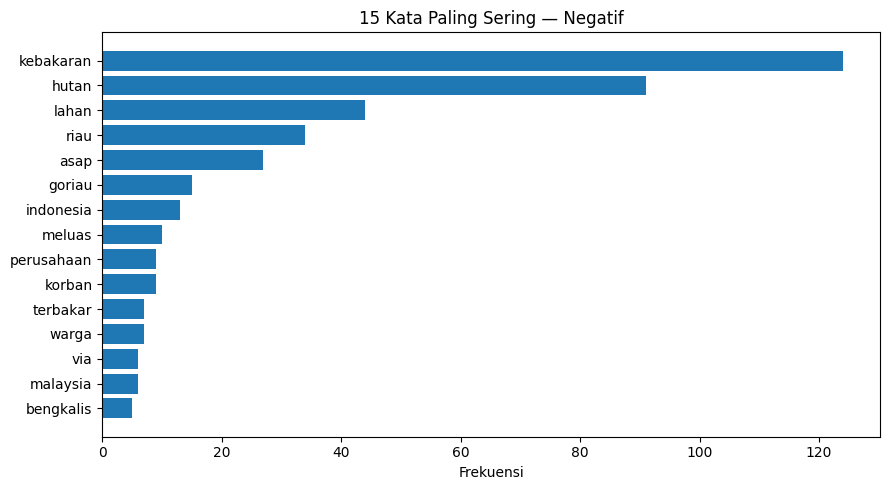

In [45]:
for category in label_order:
    text_data = " ".join(df.loc[df["sentimen"] == category, "clean_text"].astype(str))
    word_counts = Counter(text_data.split())
    common_words = word_counts.most_common(15)
    if not common_words:
        continue

    words, counts = zip(*common_words)
    plt.figure(figsize=(9, 5))
    plt.barh(list(words)[::-1], list(counts)[::-1])
    plt.title(f"15 Kata Paling Sering — {category.capitalize()}")
    plt.xlabel("Frekuensi")
    plt.tight_layout()
    plt.savefig(VIS_DIR / f"frekuensi_{category}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [46]:
X = df["clean_text"]
y = df["sentimen"]

class_counts = y.value_counts()
print("Jumlah data per kelas:")
print(class_counts)

if y.nunique() < 3:
    raise ValueError("Dataset belum memiliki ketiga kelas sentimen. Tinjau kamus dan sampel label.")
if class_counts.min() < 2:
    raise ValueError("Minimal satu kelas memiliki kurang dari 2 data. Tambah/periksa data sebelum split.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Data training:", len(X_train))
print("Data testing :", len(X_test))

Jumlah data per kelas:
sentimen
netral     180
negatif    123
positif     79
Name: count, dtype: int64
Data training: 305
Data testing : 77


In [47]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=1,
        max_df=0.98,
        sublinear_tf=True
    )),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(100,),
        activation="relu",
        solver="adam",
        max_iter=300,
        learning_rate_init=0.001,
        random_state=RANDOM_STATE
    ))
])

print(model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.98, max_features=5000,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('mlp', MLPClassifier(max_iter=300, random_state=42))])


In [48]:
print("Memulai training...")
model.fit(X_train, y_train)
print("Training selesai.")

mlp = model.named_steps["mlp"]
print("Iterasi training:", mlp.n_iter_)
print("Loss akhir:", mlp.loss_)
print("Jumlah neuron hidden:", mlp.hidden_layer_sizes)

Memulai training...
Training selesai.
Iterasi training: 174
Loss akhir: 0.007213923568368524
Jumlah neuron hidden: (100,)


In [49]:
y_pred = model.predict(X_test)
prediction_df = pd.DataFrame({
    "clean_text": X_test.reset_index(drop=True),
    "sentimen_aktual": y_test.reset_index(drop=True),
    "sentimen_prediksi": y_pred
})
display(prediction_df.head(20))

,clean_text,sentimen_aktual,sentimen_prediksi
0,kebakaran lahan hebat landa new south wales,netral,netral
1,sempat dirawat sepekan korban kebakaran hutan ...,negatif,negatif
2,metro hari kebakaran lahan pelalawan,netral,negatif
3,babinsa koramil lima puluh sosialisasi dampak ...,negatif,positif
4,info terjadi kebakaran lahan kuburan muslimin ...,negatif,negatif
5,walhi riau petani selalu jadi tumbal terjadi k...,negatif,netral
6,indonesia punya segalanya atasi kebakaran hutan,positif,netral
7,titik kebakaran lahan bertamu riau goriau,netral,positif
8,hah o sekitaran kantor tvri rumbai kebakaran l...,negatif,netral
9,gt metro tv bahas kebakaran hutan riau,netral,netral


In [50]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

metrics_df = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)"],
    "Nilai": [accuracy, precision, recall, f1]
})
display(metrics_df.style.format({"Nilai": "{:.4f}"}))

print(classification_report(y_test, y_pred, labels=label_order, zero_division=0))

,Metrik,Nilai
0,Accuracy,0.6234
1,Precision (Macro),0.6285
2,Recall (Macro),0.6166
3,F1-Score (Macro),0.6181


              precision    recall  f1-score   support

     positif       0.69      0.69      0.69        16
      netral       0.62      0.72      0.67        36
     negatif       0.58      0.44      0.50        25

    accuracy                           0.62        77
   macro avg       0.63      0.62      0.62        77
weighted avg       0.62      0.62      0.62        77



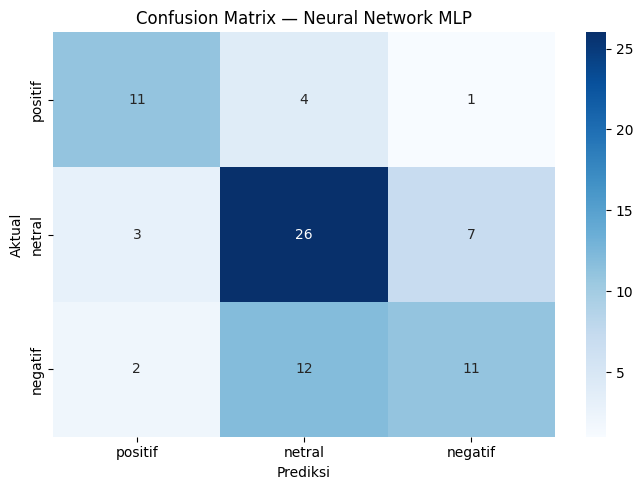

In [51]:
cm = confusion_matrix(y_test, y_pred, labels=label_order)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_order, yticklabels=label_order)
plt.title("Confusion Matrix — Neural Network MLP")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.savefig(VIS_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

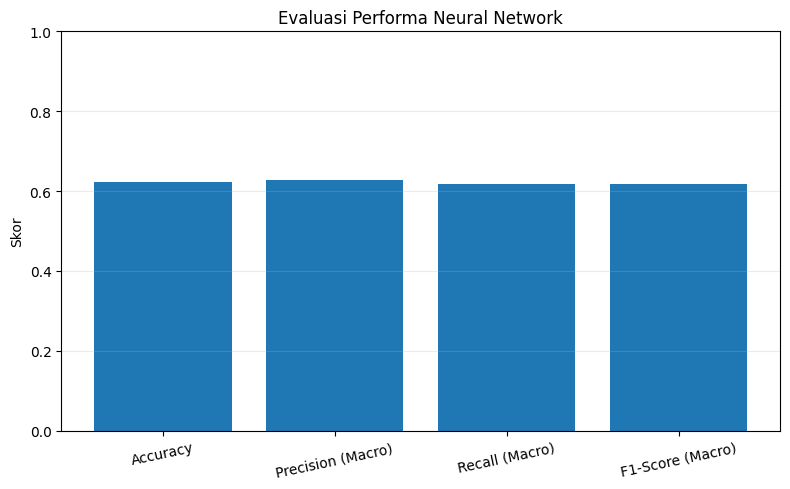

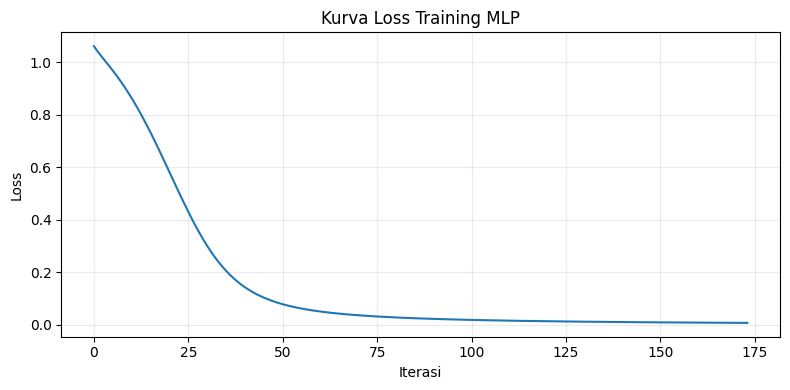

In [52]:
plt.figure(figsize=(8, 5))
plt.bar(metrics_df["Metrik"], metrics_df["Nilai"])
plt.title("Evaluasi Performa Neural Network")
plt.ylabel("Skor")
plt.ylim(0, 1)
plt.xticks(rotation=12)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(VIS_DIR / "evaluasi_model.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(mlp.loss_curve_)
plt.title("Kurva Loss Training MLP")
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(VIS_DIR / "loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [53]:
joblib.dump(model, MODEL_DIR / "model_sentimen_nn.pkl")
joblib.dump(model.named_steps["tfidf"], MODEL_DIR / "tfidf_vectorizer.pkl")

evaluation_results = {
    "accuracy": float(accuracy),
    "precision_macro": float(precision),
    "recall_macro": float(recall),
    "f1_macro": float(f1),
    "total_data": int(len(df)),
    "training_data": int(len(X_train)),
    "testing_data": int(len(X_test)),
    "model": "Multilayer Perceptron",
    "hidden_layer": 100,
    "activation": "ReLU",
    "optimizer": "Adam",
    "train_test_ratio": "80:20",
    "label_source": "Manual annotation"
}

with open(MODEL_DIR / "evaluation.json", "w", encoding="utf-8") as f:
    json.dump(evaluation_results, f, indent=4)

prediction_df.to_csv(DATA_DIR / "hasil_prediksi_testing.csv", index=False, encoding="utf-8-sig")
print(json.dumps(evaluation_results, indent=4))

{
    "accuracy": 0.6233766233766234,
    "precision_macro": 0.628498329156224,
    "recall_macro": 0.616574074074074,
    "f1_macro": 0.6180555555555555,
    "total_data": 382,
    "training_data": 305,
    "testing_data": 77,
    "model": "Multilayer Perceptron",
    "hidden_layer": 100,
    "activation": "ReLU",
    "optimizer": "Adam",
    "train_test_ratio": "80:20",
    "label_source": "Manual annotation"
}


In [54]:
EMOJI_SENTIMENT = {"positif": "😊", "netral": "😐", "negatif": "😠"}

def predict_sentiment(text):
    cleaned = clean_text(text)
    if not cleaned:
        raise ValueError("Teks kosong setelah preprocessing.")
    predicted = model.predict([cleaned])[0]
    probabilities = model.predict_proba([cleaned])[0]
    classes = model.named_steps["mlp"].classes_
    probability_dict = {label: float(prob) for label, prob in zip(classes, probabilities)}
    return {
        "teks_asli": text,
        "teks_bersih": cleaned,
        "sentimen": predicted,
        "emoji": EMOJI_SENTIMENT[predicted],
        "probabilitas": probability_dict
    }

contoh_teks = "Asap kebakaran semakin parah dan mengganggu kesehatan warga."
hasil = predict_sentiment(contoh_teks)
print(hasil)

{'teks_asli': 'Asap kebakaran semakin parah dan mengganggu kesehatan warga.', 'teks_bersih': 'asap kebakaran semakin parah mengganggu kesehatan warga', 'sentimen': np.str_('negatif'), 'emoji': '😠', 'probabilitas': {np.str_('negatif'): 0.9929247277527972, np.str_('netral'): 0.003532319806679432, np.str_('positif'): 0.003542952440523278}}


In [55]:
%%writefile /content/analisis_sentimen_kebakaran_hutan/app_sentimen_nn.py
import os
import sys
import json
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, BASE_DIR)
from preprocessing import clean_text

MODEL_PATH = os.path.join(BASE_DIR, "models", "model_sentimen_nn.pkl")
DATA_PATH = os.path.join(BASE_DIR, "data", "dataset_sentimen.csv")
EVAL_PATH = os.path.join(BASE_DIR, "models", "evaluation.json")
VIS_DIR = os.path.join(BASE_DIR, "visualisasi")

st.set_page_config(
    page_title="Analisis Sentimen Kebakaran Hutan",
    page_icon="🌳",
    layout="wide"
)

@st.cache_resource
def load_model():
    import joblib
    return joblib.load(MODEL_PATH)

@st.cache_data
def load_data():
    return pd.read_csv(DATA_PATH)

@st.cache_data
def load_evaluation():
    with open(EVAL_PATH, "r", encoding="utf-8") as file:
        return json.load(file)

required_files = [MODEL_PATH, DATA_PATH, EVAL_PATH]
if not all(os.path.exists(path) for path in required_files):
    st.error("File model, dataset, atau evaluasi belum tersedia. Jalankan seluruh cell training di notebook terlebih dahulu.")
    st.stop()

model = load_model()
df = load_data()
evaluation = load_evaluation()

st.title("🌳 Analisis Sentimen Kebakaran Hutan")
st.caption("Analisis teks masyarakat mengenai kebakaran hutan menggunakan TF-IDF dan Neural Network Multilayer Perceptron.")

st.sidebar.title("Navigasi")
menu = st.sidebar.radio(
    "Pilih halaman",
    ["Dashboard", "Visualisasi Sentimen", "Evaluasi Model", "Prediksi Sentimen"]
)
st.sidebar.divider()
st.sidebar.caption("Proyek praktikum analisis sentimen")

if menu == "Dashboard":
    st.header("Ringkasan Dataset")
    counts = df["sentimen"].value_counts()
    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Total Tweet", f"{len(df):,}")
    col2.metric("Positif", int(counts.get("positif", 0)))
    col3.metric("Netral", int(counts.get("netral", 0)))
    col4.metric("Negatif", int(counts.get("negatif", 0)))

    st.subheader("Distribusi Sentimen")
    left, right = st.columns(2)
    with left:
        path = os.path.join(VIS_DIR, "distribusi_bar.png")
        if os.path.exists(path):
            st.image(path, caption="Diagram batang distribusi sentimen", use_container_width=True)
    with right:
        path = os.path.join(VIS_DIR, "distribusi_pie.png")
        if os.path.exists(path):
            st.image(path, caption="Diagram lingkaran distribusi sentimen", use_container_width=True)

    st.subheader("Contoh Data Penelitian")
    display_columns = [c for c in ["created_at", "username", "full_text", "clean_text", "sentimen"] if c in df.columns]
    st.dataframe(df[display_columns].head(25), use_container_width=True, hide_index=True)
    st.download_button(
        "Unduh dataset CSV",
        data=df.to_csv(index=False).encode("utf-8-sig"),
        file_name="dataset_sentimen.csv",
        mime="text/csv"
    )

elif menu == "Visualisasi Sentimen":
    st.header("Visualisasi Kata")
    for category in ["positif", "netral", "negatif"]:
        st.subheader(f"WordCloud {category.capitalize()}")
        image_path = os.path.join(VIS_DIR, f"wordcloud_{category}.png")
        if os.path.exists(image_path):
            st.image(image_path, use_container_width=True)
        else:
            st.info(f"WordCloud {category} belum tersedia.")
        freq_path = os.path.join(VIS_DIR, f"frekuensi_{category}.png")
        if os.path.exists(freq_path):
            st.image(freq_path, caption=f"15 kata paling sering pada sentimen {category}", use_container_width=True)
        st.divider()

elif menu == "Evaluasi Model":
    st.header("Evaluasi Model Neural Network")
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Accuracy", f"{evaluation['accuracy'] * 100:.2f}%")
    c2.metric("Precision Macro", f"{evaluation['precision_macro'] * 100:.2f}%")
    c3.metric("Recall Macro", f"{evaluation['recall_macro'] * 100:.2f}%")
    c4.metric("F1-Score Macro", f"{evaluation['f1_macro'] * 100:.2f}%")

    cm_path = os.path.join(VIS_DIR, "confusion_matrix.png")
    if os.path.exists(cm_path):
        st.subheader("Confusion Matrix")
        st.image(cm_path, use_container_width=True)
    eval_path = os.path.join(VIS_DIR, "evaluasi_model.png")
    if os.path.exists(eval_path):
        st.subheader("Perbandingan Metrik")
        st.image(eval_path, use_container_width=True)
    loss_path = os.path.join(VIS_DIR, "loss_curve.png")
    if os.path.exists(loss_path):
        st.subheader("Kurva Loss Training")
        st.image(loss_path, use_container_width=True)
    st.subheader("Konfigurasi Model")
    st.json({
        "Model": evaluation["model"],
        "Hidden layer": evaluation["hidden_layer"],
        "Activation": evaluation["activation"],
        "Optimizer": evaluation["optimizer"],
        "Training data": evaluation["training_data"],
        "Testing data": evaluation["testing_data"]
    })

elif menu == "Prediksi Sentimen":
    st.header("Prediksi Teks Baru")
    user_text = st.text_area(
        "Masukkan teks mengenai kebakaran hutan",
        placeholder="Contoh: Petugas berhasil memadamkan api dan warga kembali aman.",
        height=140
    )
    if st.button("Analisis Sentimen", type="primary"):
        if not user_text.strip():
            st.warning("Masukkan teks terlebih dahulu.")
        else:
            cleaned = clean_text(user_text)
            if not cleaned:
                st.warning("Teks tidak memiliki kata yang dapat diproses.")
            else:
                predicted = model.predict([cleaned])[0]
                probabilities = model.predict_proba([cleaned])[0]
                classes = model.named_steps["mlp"].classes_
                emoji = {"positif": "😊", "netral": "😐", "negatif": "😠"}
                st.divider()
                st.success(f"Hasil sentimen: {predicted.upper()} {emoji[predicted]}")
                st.write("Teks setelah preprocessing:")
                st.info(cleaned)
                probability_df = pd.DataFrame({
                    "Sentimen": classes,
                    "Probabilitas": [float(value) * 100 for value in probabilities]
                }).set_index("Sentimen")
                st.subheader("Probabilitas Prediksi")
                st.bar_chart(probability_df)
                for label, value in zip(classes, probabilities):
                    st.write(f"{label.capitalize()}: {value * 100:.2f}%")

st.divider()
st.caption("Catatan: model dilatih menggunakan label sentimen hasil anotasi manual. Probabilitas model bukan kepastian sentimen masyarakat.")


Writing /content/analisis_sentimen_kebakaran_hutan/app_sentimen_nn.py


In [69]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb \
    -O /content/cloudflared.deb

!apt-get install -y /content/cloudflared.deb

!cloudflared --version

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'cloudflared' instead of '/content/cloudflared.deb'
The following NEW packages will be installed:
  cloudflared
0 upgraded, 1 newly installed, 0 to remove and 48 not upgraded.
Need to get 0 B/19.9 MB of archives.
After this operation, 40.3 MB of additional disk space will be used.
Get:1 /content/cloudflared.deb cloudflared amd64 2026.11.0 [19.9 MB]
Selecting previously unselected package cloudflared.
(Reading database ... 123112 files and directories currently installed.)
Preparing to unpack /content/cloudflared.deb ...
Unpacking cloudflared (2026.11.0) ...
Setting up cloudflared (2026.11.0) ...
Processing triggers for man-db (2.12.0-4build2) ...
cloudflared version 2026.11.0 (built 2026-11-12-12:17 UTC)


In [70]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )

    print("Status:", response.status_code)

    if response.status_code == 200:
        print("Streamlit berhasil berjalan!")

except requests.RequestException as e:
    print("Streamlit belum berjalan:", e)

Status: 200
Streamlit berhasil berjalan!


In [ ]:
!cloudflared tunnel --no-autoupdate --url http://localhost:8501

2026-11-15T10:36:07Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-15T10:36:07Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-15T10:36:11Z INF +--------------------------------------------------------------------------------------------+
2026-11-15T10:36:11Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-15T10:36:11Z INF |  https://next-howto-character-achieve.trycloudflare.co